# A. Python Essentials for Signal Processing

This appendix collects the Python operations I use throughout the book. You do not need to learn every feature of each library before starting. It is more useful to understand how an array represents a recording, how sample indices become seconds, and how to check the result of a calculation.

We will work through small examples before using ECG data. I will point out details that can quietly change an analysis, including array shapes, units, integer overflow, and filtering before downsampling. You can read this appendix in order or return to a section when a chapter uses an unfamiliar operation.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

## A.1 Arrays, Data Types and Vectorization

The central object of scientific Python is the NumPy array, `np.ndarray`. Unlike a Python list, which can hold any mixture of objects scattered around memory, an array is one contiguous block of numbers that all share a single **data type** (`dtype`), together with a **shape** that says how the block is organized into rows and columns. Those two restrictions are what make arrays fast: the computer knows exactly where every number lives and how to add or multiply it.

We start by reading the first 10 s of record 100. The `wfdb` reader returns a record object whose `p_signal` attribute holds the physical signal (here in millivolts) as a two-dimensional array with one row per sample and one column per channel.

In [2]:
rec = wfdb.rdrecord("../data/mitdb/100", sampto=3600)   # first 10 s
fs = rec.fs
ecg = rec.p_signal[:, 0]                                  # lead MLII, mV

print(f"rec.p_signal : shape {rec.p_signal.shape}, dtype {rec.p_signal.dtype}")
print(f"channels     : {rec.sig_name}, units {rec.units}")
print(f"ecg          : shape {ecg.shape}, {ecg.nbytes} bytes, fs = {fs} Hz")

rec.p_signal : shape (3600, 2), dtype float64
channels     : ['MLII', 'V5'], units ['mV', 'mV']
ecg          : shape (3600,), 28800 bytes, fs = 360 Hz


The shape `(3600, 2)` reads as 3600 samples by 2 channels, and selecting column 0 gives a one-dimensional array of 3600 values. Each `float64` number occupies 8 bytes, hence 28,800 bytes for 10 s of one lead.

### Vectorized arithmetic

Arithmetic on arrays acts element by element, and the loop over elements runs in compiled code rather than in the Python interpreter. This style is called **vectorization**. Converting to microvolts, removing the mean, computing an RMS value or a first difference are each a single expression:

In [3]:
ecg_uv = 1000 * ecg                    # mV -> µV, every sample at once
centered = ecg - ecg.mean()
rms = np.sqrt(np.mean(centered**2))
slope = np.diff(ecg) * fs              # first difference scaled to mV/s

print(f"mean {ecg.mean():+.3f} mV, min {ecg.min():+.3f} mV, max {ecg.max():+.3f} mV")
print(f"first sample in µV: {ecg_uv[0]:.0f}")
print(f"RMS after removing the mean: {rms:.3f} mV")
print(f"steepest upstroke: {slope.max():.1f} mV/s at t = {np.argmax(slope) / fs:.3f} s")
print(f"np.diff shortens the signal: {ecg.size} -> {slope.size} samples")

mean -0.320 mV, min -0.645 mV, max +0.960 mV
first sample in µV: -145
RMS after removing the mean: 0.170 mV
steepest upstroke: 104.4 mV/s at t = 1.831 s
np.diff shortens the signal: 3600 -> 3599 samples


Notice the last line. `np.diff(x)` returns `x[1:] - x[:-1]`, which has one sample fewer than `x`; forgetting this is a common source of length mismatches when the derivative is later plotted against the original time vector.

### Reductions along an axis

Functions such as `mean`, `std`, `min`, `max` and `sum` *reduce* an array to fewer numbers. For a two-dimensional array the `axis` argument chooses which dimension is collapsed: `axis=0` collapses the rows (samples) and leaves one value per channel, `axis=1` collapses the columns and leaves one value per sample.

In [4]:
both = rec.p_signal
print("per-channel mean (axis=0):", both.mean(axis=0), "mV")
print("per-channel std  (axis=0):", both.std(axis=0), "mV")
print("per-sample mean of the two leads (axis=1), shape:", both.mean(axis=1).shape)

per-channel mean (axis=0): [-0.3199 -0.2032] mV
per-channel std  (axis=0): [0.1702 0.1225] mV
per-sample mean of the two leads (axis=1), shape: (3600,)


### Creating arrays

The constructors used most often in this book are `np.zeros(n)`, `np.ones(n)`, `np.full(n, value)`, `np.arange(start, stop, step)` and `np.linspace(start, stop, num)`. All of them default to `float64`, which is the right choice for signal processing: 64-bit floats carry about 16 significant digits, far more than any biomedical ADC delivers. Integer arrays (`np.zeros(5, dtype=np.int16)`) appear mainly when reading raw ADC codes, and they deserve care, as A.8 shows.

## A.2 Time Vectors, Indexing and Slicing

A sampled signal is just an array of numbers. The physical time of sample $n$ is $t_n = n/f_s = n\,T_s$, so we build the time vector from the sample indices:

In [5]:
t = np.arange(ecg.size) / fs           # 0, 1/fs, 2/fs, ...  (s)
print(f"t[0] = {t[0]} s, t[1] = {t[1]:.6f} s, t[-1] = {t[-1]:.6f} s, length {t.size}")

t[0] = 0.0 s, t[1] = 0.002778 s, t[-1] = 9.997222 s, length 3600


Building `t` from integer indices is safer than `np.arange(0, 10, 1 / fs)`, whose floating-point step can produce one sample more or fewer than expected; A.8 gives a concrete example. The last time stamp is $3599/360 = 9.9972$ s, not 10 s, because the samples are numbered from zero.

### From seconds to samples

To cut a window from $t_1$ to $t_2$ we convert both times to sample indices and slice. Python slices `x[start:stop]` include `start` and exclude `stop`, so the slice holds exactly `stop - start` samples. A 2-s window at 360 Hz therefore has 720 samples, and consecutive windows `x[0:720]`, `x[720:1440]` tile the signal without overlap or gaps.

In [6]:
def sec_to_idx(seconds, fs):
    """Nearest sample index for a time given in seconds."""
    return int(round(seconds * fs))


i1, i2 = sec_to_idx(1.0, fs), sec_to_idx(3.0, fs)
window = ecg[i1:i2]
print(f"samples {i1}..{i2 - 1}: {window.size} samples = {window.size / fs:.2f} s")
print(f"last 3 samples  : {ecg[-3:]}")
print(f"every 4th sample: {ecg[:16:4]}  (naive decimation, see Section 9.2)")

samples 360..1079: 720 samples = 2.00 s
last 3 samples  : [-0.39  -0.4   -0.405]
every 4th sample: [-0.145 -0.145 -0.12  -0.16 ]  (naive decimation, see Section 9.2)


Negative indices count from the end, and a third number in the slice is a step. Taking every fourth sample, `ecg[::4]`, lowers the sampling rate to 90 Hz but does nothing to prevent aliasing; Section 6.2 explains why a proper decimator filters first.

### Boolean masks and fancy indexing

A comparison such as `ecg > 0.8` returns a Boolean array of the same shape, and indexing with it keeps the samples where it is `True`. Masks combine with `&` (and), `|` (or) and `~` (not). Each comparison must be wrapped in parentheses, because `&` binds more tightly than `>` in Python.

Indexing with an *integer* array, called fancy indexing, picks out arbitrary samples. The annotation file of record 100 stores the sample index of every beat, so `ecg[r_idx]` returns the ECG amplitude at all annotated beats at once.

In [7]:
mask = (t >= 2) & (t < 4)
print(f"samples with 2 s <= t < 4 s: {mask.sum()}")
print(f"samples above 0.8 mV       : {np.count_nonzero(ecg > 0.8)}")

ann = wfdb.rdann("../data/mitdb/100", "atr", sampto=3600)
symbols = np.array(ann.symbol)
is_beat = np.isin(symbols, ["N", "A", "V"])
r_idx = ann.sample[is_beat]
r_amp = ecg[r_idx]
print(f"annotated beats in 10 s    : {r_idx.size} ({', '.join(f'{s}: {np.sum(symbols == s)}' for s in ['N', 'A'])})")
print(f"amplitude at the beat marks: {r_amp.mean():.2f} ± {r_amp.std():.2f} mV")

samples with 2 s <= t < 4 s: 720
samples above 0.8 mV       : 26
annotated beats in 10 s    : 13 (N: 12, A: 1)
amplitude at the beat marks: 0.87 ± 0.05 mV


### Views and copies

Slicing does not copy data. `seg = ecg[100:200]` is a **view** that looks into the memory of `ecg`, so writing into `seg` silently changes `ecg` as well. This is efficient but occasionally surprising; call `.copy()` whenever a modified segment must not affect the original. Fancy and Boolean indexing, by contrast, always return copies.

In [8]:
x = ecg.copy()
seg = x[:3]
seg[:] = 0.0                                   # writes through to x
print(f"x[:3] after editing the view: {x[:3]}, shares memory: {np.shares_memory(seg, x)}")
print(f"fancy indexing shares memory : {np.shares_memory(x[[0, 1, 2]], x)}")

x[:3] after editing the view: [0. 0. 0.], shares memory: True
fancy indexing shares memory : False


The figure below combines the pieces: a time vector in seconds, a window selected by a Boolean mask, and the beat annotations placed with fancy indexing.

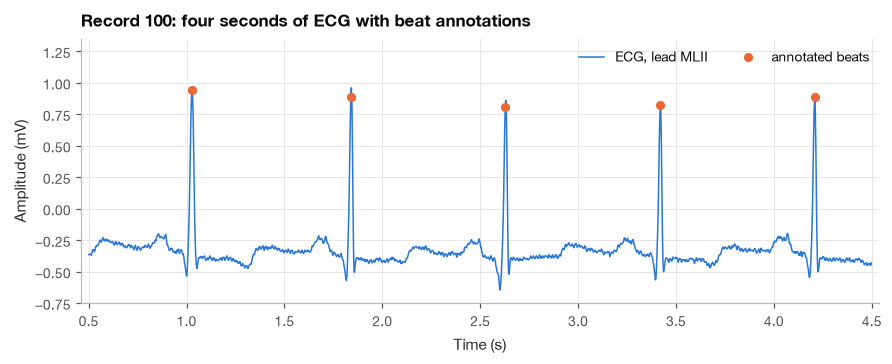

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.2))
show = (t >= 0.5) & (t < 4.5)
ax.plot(t[show], ecg[show], color=C[0], lw=1.0, label="ECG, lead MLII")
in_view = (r_idx >= sec_to_idx(0.5, fs)) & (r_idx < sec_to_idx(4.5, fs))
ax.plot(t[r_idx[in_view]], ecg[r_idx[in_view]], "o", color=C[1], ms=5, label="annotated beats")
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)", ylim=(-0.75, 1.35),
       title="Record 100: four seconds of ECG with beat annotations")
ax.legend(loc="upper right", ncols=2)
plt.show()

## A.3 Broadcasting: Cutting a Recording into Beats

NumPy can combine arrays of different shapes as long as the shapes are compatible, a mechanism called **broadcasting**. The rule compares the shapes from the last dimension backwards: two dimensions are compatible when they are equal or when one of them is 1, and a dimension of size 1 is stretched (without copying) to match the other. A missing leading dimension counts as 1. A column of shape `(3, 1)` plus a row of shape `(4,)` therefore produces a `(3, 4)` table:

In [10]:
col = np.array([[0], [10], [20]])     # shape (3, 1)
row = np.array([0, 1, 2, 3])          # shape (4,), treated as (1, 4)
print(col + row)

[[ 0  1  2  3]
 [10 11 12 13]
 [20 21 22 23]]


I find this small trick to be one of the most useful in ECG work. Suppose we want every heartbeat of the first minute of record 100 as a row of a matrix, from 250 ms before to 450 ms after the beat annotation. The beat positions form a column, the offsets form a row, and their broadcast sum is a matrix of sample indices. Indexing the ECG with that matrix returns the matrix of beats in one step, with no loop.

In [11]:
rec60 = wfdb.rdrecord("../data/mitdb/100", sampto=60 * fs)
ecg60 = rec60.p_signal[:, 0]
ann60 = wfdb.rdann("../data/mitdb/100", "atr", sampto=60 * fs)
r60 = ann60.sample[np.array(ann60.symbol) == "N"]

offsets = np.arange(-sec_to_idx(0.25, fs), sec_to_idx(0.45, fs))    # samples around the beat
inside = (r60 + offsets[0] >= 0) & (r60 + offsets[-1] < ecg60.size)
idx = r60[inside, None] + offsets[None, :]                           # (n_beats, n_offsets)
beats = ecg60[idx]
beats = beats - np.median(beats, axis=1, keepdims=True)              # (n, L) - (n, 1)

print(f"index matrix shape : {idx.shape}")
print(f"beat matrix shape  : {beats.shape}  ({beats.shape[0]} beats x {beats.shape[1]} samples)")

index matrix shape : (72, 252)
beat matrix shape  : (72, 252)  (72 beats x 252 samples)


The line that removes the baseline also relies on broadcasting. `np.median(beats, axis=1, keepdims=True)` returns one value per beat with shape `(n, 1)` rather than `(n,)`, so subtracting it from the `(n, L)` matrix removes each beat's own median level. Without `keepdims=True` the shapes `(n, L)` and `(n,)` would not line up from the right, and NumPy would raise an error (or, worse, broadcast along the wrong axis if `n` happened to equal `L`).

The same pattern refines the annotation positions. We look 50 ms to either side of each mark, find the largest sample in each row with `argmax(axis=1)`, and add the winning offset back:

In [12]:
search = np.arange(-sec_to_idx(0.05, fs), sec_to_idx(0.05, fs) + 1)
local = ecg60[r60[inside, None] + search[None, :]]
r_refined = r60[inside] + search[np.argmax(local, axis=1)]
shift_ms = 1000 * (r_refined - r60[inside]) / fs
print(f"shift from annotation to local maximum: median {np.median(shift_ms):.1f} ms, "
      f"range {shift_ms.min():.1f} to {shift_ms.max():.1f} ms")

shift from annotation to local maximum: median 0.0 ms, range 0.0 to 5.6 ms


The annotations of record 100 sit within a few milliseconds of the R-wave maximum, which is what we expect from a carefully reviewed database. The averaged beat below is computed with a single `beats.mean(axis=0)`; beat averaging as a noise reduction method returns in Section 10.1, and beat matrices of exactly this kind are the starting point of the morphology analysis in Section 19.3.

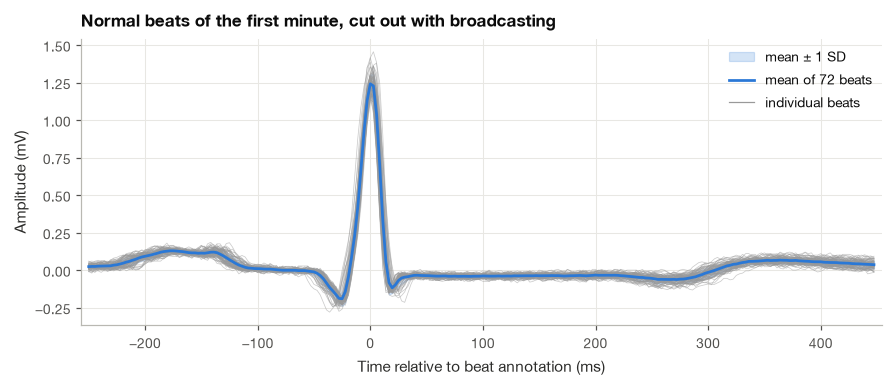

In [13]:
t_beat = 1000 * offsets / fs                       # ms relative to the annotation
mean_beat = beats.mean(axis=0)
sd_beat = beats.std(axis=0)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(t_beat, beats.T, color="0.6", lw=0.5, alpha=0.5)
ax.fill_between(t_beat, mean_beat - sd_beat, mean_beat + sd_beat, color=C[0], alpha=0.2,
                label="mean ± 1 SD")
ax.plot(t_beat, mean_beat, color=C[0], lw=1.8, label=f"mean of {beats.shape[0]} beats")
ax.plot([], [], color="0.6", lw=0.8, label="individual beats")
ax.set(xlabel="Time relative to beat annotation (ms)", ylabel="Amplitude (mV)",
       title="Normal beats of the first minute, cut out with broadcasting")
ax.legend(loc="upper right")
plt.show()

## A.4 Figures with Matplotlib

Matplotlib offers two interfaces. The quick one (`plt.plot(...)`) draws on whatever axes happen to be active, which is convenient at the prompt and confusing in longer scripts. Every figure in this book uses the object-oriented interface instead: `plt.subplots` returns a figure object `fig` and one or more axes objects `ax`, and we call methods on the axes explicitly. The book's appearance comes from a shared style file loaded once in the setup cell, `plt.style.use("../bsp.mplstyle")`, which sets fonts, grid lines, the color cycle and constrained layout so that labels do not overlap.

The conventions I follow are simple. Time series are plotted against time in seconds, never against sample number. Every axis label carries a unit. The main signal is drawn in `C[0]` (blue) and highlighted points or a processed version in `C[1]` (orange). Stacked panels that share a time axis are created with `sharex=True`, so zooming one panel zooms all of them and only the bottom panel needs tick labels. The cell below follows these rules for the two leads of record 100 and shades one QRS complex with `axvspan`. The beat marks are drawn on lead MLII only, because the annotation times were placed on that lead and the R wave in V5 peaks at a slightly different instant.

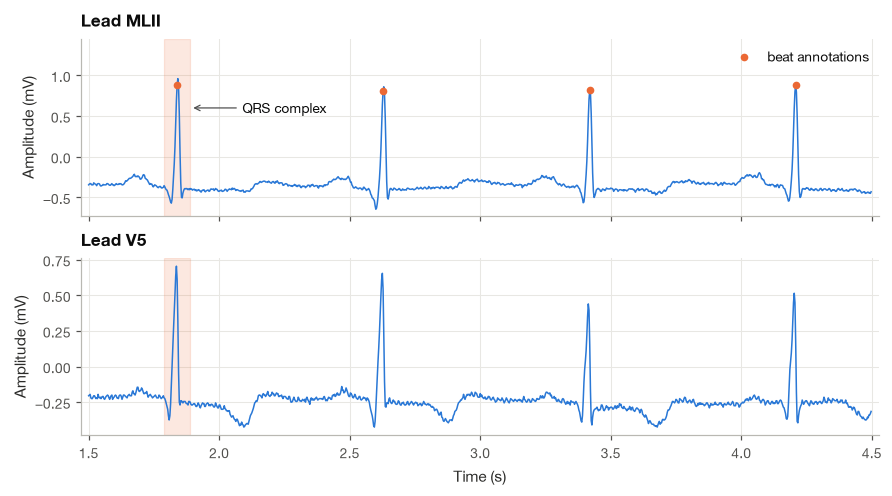

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.4), sharex=True)
show = (t >= 1.5) & (t < 4.5)
r_view = r_idx[(t[r_idx] >= 1.5) & (t[r_idx] < 4.5)]
t_qrs = t[r_view[0]]

for ch, ax in enumerate(axes):
    lead = rec.p_signal[:, ch]
    ax.plot(t[show], lead[show], color=C[0], lw=1.0)
    ax.axvspan(t_qrs - 0.05, t_qrs + 0.05, color=C[1], alpha=0.15)
    ax.set(ylabel="Amplitude (mV)", title=f"Lead {rec.sig_name[ch]}")
axes[0].plot(t[r_view], rec.p_signal[r_view, 0], "o", color=C[1], ms=4, label="beat annotations")
axes[0].annotate("QRS complex", xy=(t_qrs + 0.05, 0.6), xytext=(t_qrs + 0.25, 0.6),
                 va="center", fontsize=9, arrowprops=dict(arrowstyle="->", color="0.3", lw=0.8))
axes[0].set_ylim(top=1.45)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Time (s)")
plt.show()

A few further habits keep figures honest and light. Plot a meaningful window (a few beats, a few seconds of EEG) rather than squeezing half an hour into one line; for long overviews, decimate the trace for display only. Use `ax.set(xlabel=..., ylabel=..., title=...)` to set several properties at once. End plotting cells with `plt.show()`. To save a figure for a paper, `fig.savefig("ecg.pdf")` writes a vector file that stays sharp at any zoom, while `fig.savefig("ecg.png", dpi=300)` writes a raster image.

## A.5 Complex Arrays and a Quick FFT

NumPy stores complex numbers natively, using the engineering symbol `j` for the imaginary unit ([Section 2.1](../ch02_math_toolkit/01_complex_numbers.ipynb)). A `complex128` array holds a 64-bit real part and a 64-bit imaginary part per element, and the familiar operations are all vectorized:

In [15]:
z = np.array([3 + 4j, -1 - 1j, 2j])
print(f"dtype        : {z.dtype}")
print(f"real, imag   : {z.real}, {z.imag}")
print(f"|z|          : {np.abs(z)}")
print(f"angle (rad)  : {np.angle(z)}")
print(f"conjugate    : {np.conj(z)}")
print(f"unit phasors : {np.exp(1j * np.array([0, np.pi / 2, np.pi]))}")

dtype        : complex128
real, imag   : [ 3. -1.  0.], [ 4. -1.  2.]
|z|          : [5.     1.4142 2.    ]
angle (rad)  : [ 0.9273 -2.3562  1.5708]
conjugate    : [ 3.-4.j -1.+1.j  0.-2.j]
unit phasors : [ 1.+0.j  0.+1.j -1.+0.j]


The fast Fourier transform lives in `np.fft`. For a real signal of length $N$ we use `np.fft.rfft`, which returns only the $N/2 + 1$ non-negative frequency bins (the negative-frequency half is the complex conjugate mirror image and carries no new information), and `np.fft.rfftfreq(N, d=1/fs)` gives the frequency of each bin, $f_k = k f_s / N$. For a sinusoid that completes a whole number of cycles in the record, the amplitude in its bin is $2\lvert X[k]\rvert/N$. We check this scaling on a test signal before trusting it on real data.

In [16]:
n = np.arange(10 * fs)
test = 0.8 * np.cos(2 * np.pi * 12 * n / fs) + 0.3 * np.cos(2 * np.pi * 50 * n / fs + 1.0)
X = np.fft.rfft(test)
f = np.fft.rfftfreq(test.size, d=1 / fs)
amp = 2 * np.abs(X) / test.size

print(f"N = {test.size}, {X.size} bins, resolution fs/N = {f[1]:.2f} Hz")
for f0 in (12, 50):
    k = np.argmin(np.abs(f - f0))
    print(f"{f0:>3} Hz: amplitude {amp[k]:.3f}, phase {np.angle(X[k]):+.3f} rad")

N = 3600, 1801 bins, resolution fs/N = 0.10 Hz
 12 Hz: amplitude 0.800, phase -0.000 rad
 50 Hz: amplitude 0.300, phase +1.000 rad


Both amplitudes come back exactly (0.8 and 0.3), and the phase of the 50 Hz component is the 1.0 rad we put in. Applied to the first minute of the ECG, the same three lines reveal a spectrum built from peaks at the heart rate and its harmonics, the signature of a nearly periodic waveform (Chapter 5).

resolution 0.0167 Hz; mean RR 0.812 s (SD 37 ms) -> heart rate 73.9 bpm = 1.231 Hz


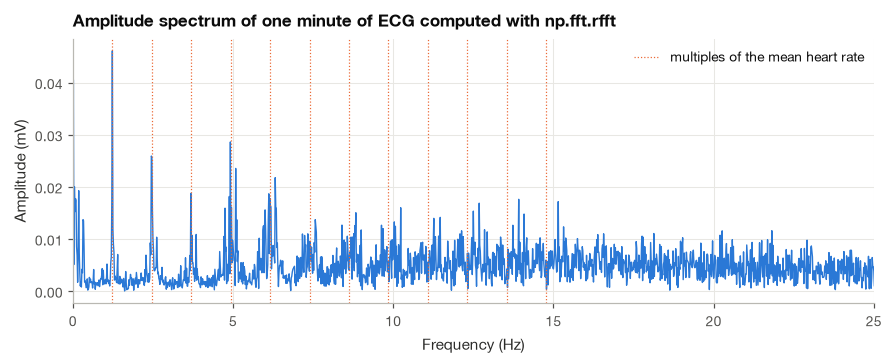

In [17]:
x = ecg60 - ecg60.mean()
X_ecg = np.fft.rfft(x)
f_ecg = np.fft.rfftfreq(x.size, d=1 / fs)
amp_ecg = 2 * np.abs(X_ecg) / x.size

rr60 = np.diff(ann60.sample[np.isin(ann60.symbol, ["N", "A", "V"])]) / fs
f_hr = 1 / rr60.mean()
print(f"resolution {f_ecg[1]:.4f} Hz; mean RR {rr60.mean():.3f} s (SD {1000 * rr60.std():.0f} ms) "
      f"-> heart rate {60 * f_hr:.1f} bpm = {f_hr:.3f} Hz")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(f_ecg, amp_ecg, color=C[0], lw=0.9)
for h in range(1, 13):
    ax.axvline(h * f_hr, color=C[1], lw=0.8, ls=":", label="multiples of the mean heart rate" if h == 1 else None)
ax.set(xlim=(0, 25), xlabel="Frequency (Hz)", ylabel="Amplitude (mV)",
       title="Amplitude spectrum of one minute of ECG computed with np.fft.rfft")
ax.legend(loc="upper right")
plt.show()

The first few harmonics stand out as sharp peaks, but they broaden and merge into a continuum above about 8 Hz. The reason is physiological: the RR interval changes a little from beat to beat, so the fundamental wanders over a small band, and the $h$-th harmonic wanders over a band $h$ times wider. Choosing the record length, windowing and interpreting such spectra is the subject of Chapter 10, and Section 10.5 studies the ECG spectrum in detail.

## A.6 A Tour of `scipy.signal`

`scipy.signal` contains most of the classical routines used in this book. The table lists the ones you will meet most often and where they are developed.

| Task | Function | Developed in |
|---|---|---|
| IIR filter design | `signal.butter`, `signal.cheby1`, `signal.ellip` (use `output="sos"`) | Chapter 15 |
| FIR filter design | `signal.firwin`, `signal.remez` | Chapter 9 |
| Causal / zero-phase filtering | `signal.sosfilt` / `signal.sosfiltfilt` | Section 15.3 |
| Frequency response | `signal.freqz`, `signal.sosfreqz` | Section 8.4 |
| Peak detection | `signal.find_peaks` | Section 19.1 |
| Power spectral density | `signal.welch`, `signal.periodogram` | Section 7.3 |
| Resampling | `signal.resample_poly`, `signal.decimate` | Section 9.3 |
| Time-frequency analysis | `signal.stft`, `signal.spectrogram` | Section 23.2 |
| Analytic signal | `signal.hilbert` | Section 23.4 |

Two conventions save trouble with these functions. First, I recommend passing the sampling rate explicitly (`fs=fs`) to every design and analysis routine, so that cutoff frequencies are given in hertz rather than as fractions of the Nyquist frequency. Second, IIR filters should be designed and applied in second-order sections (`output="sos"` with `sosfilt` or `sosfiltfilt`), because the alternative polynomial form `(b, a)` becomes numerically fragile at higher orders.

Resampling is a good first example because it is a single call. `signal.resample_poly(x, up, down)` changes the sampling rate by the rational factor `up/down` and applies an anti-aliasing filter on the way. To bring the 360 Hz MIT-BIH signal to the 125 Hz of the BIDMC database, the factor is $125/360 = 25/72$:

In [18]:
ecg125 = signal.resample_poly(ecg60, up=25, down=72)
print(f"{ecg60.size} samples at {fs} Hz -> {ecg125.size} samples at 125 Hz "
      f"(duration {ecg60.size / fs:.1f} s -> {ecg125.size / 125:.1f} s)")

r_all60 = ann60.sample[np.isin(ann60.symbol, ["N", "A", "V"])]
w360, w125 = sec_to_idx(0.05, fs), sec_to_idx(0.05, 125)
peak360 = ecg60[r_all60[:, None] + np.arange(-w360, w360 + 1)].max(axis=1)
k125 = np.round(r_all60 * 125 / fs).astype(int)
peak125 = ecg125[k125[:, None] + np.arange(-w125, w125 + 1)].max(axis=1)
change = peak125 - peak360
print(f"R-peak change over {change.size} beats: mean {change.mean():+.3f} mV "
      f"({100 * np.mean(change / peak360):+.1f} %), range {change.min():+.3f} to {change.max():+.3f} mV")

21600 samples at 360 Hz -> 7500 samples at 125 Hz (duration 60.0 s -> 60.0 s)
R-peak change over 74 beats: mean -0.036 mV (-4.2 %), range -0.172 to +0.037 mV


The duration is preserved exactly, but the R-wave amplitudes are not. Measured beat by beat (with the broadcasting trick of A.3), the peaks at 125 Hz are on average about 4 % lower than at 360 Hz, and individual beats change by anything between −0.17 and +0.04 mV. At 125 Hz the samples are 8 ms apart and rarely fall right on the apex of a QRS complex that rises and falls within about 40 ms, and the anti-aliasing filter both rounds the sharpest peaks and can overshoot a little next to them. For heart-rate analysis this hardly matters, but for amplitude measurements it does, which is one reason ECG standards ask for sampling rates of 500 Hz or more (Section 11.2). The remaining functions of the table appear in the walkthrough that follows.

## A.7 An ECG Workflow, Step by Step

This subsection strings the tools together into the kind of short pipeline I write at the start of almost every ECG project: load a record, look at it, inspect its spectrum, filter it, detect the beats and tabulate the result. To make the filtering meaningful we contaminate the clean record 100 with real noise recorded by the MIT-BIH Noise Stress Test Database, then check every result against the clean signal and the reference annotations. Each step is small on purpose; Chapter 12 develops each of them properly.

### Step 1: Load one minute of ECG, its annotations and real noise

The NSTDB records `ma` (muscle artifact) and `bw` (baseline wander) were recorded from active volunteers with electrodes placed where the ECG is weak, so they contain realistic noise and almost no cardiac signal. Both are sampled at 360 Hz like the MIT-BIH records, so we can add them sample by sample.

In [19]:
n_samp = 60 * fs
clean = wfdb.rdrecord("../data/mitdb/100", sampto=n_samp).p_signal[:, 0]
ann1 = wfdb.rdann("../data/mitdb/100", "atr", sampto=n_samp)
beat_mask = np.isin(ann1.symbol, ["N", "A", "V"])
r_ref, sym_ref = ann1.sample[beat_mask], np.array(ann1.symbol)[beat_mask]

ma = wfdb.rdrecord("../data/nstdb/ma", sampto=n_samp).p_signal[:, 0]
bw = wfdb.rdrecord("../data/nstdb/bw", sampto=n_samp).p_signal[:, 0]
t1 = np.arange(n_samp) / fs
print(f"clean ECG {clean.size} samples, {r_ref.size} reference beats")
print(f"noise SD: muscle {ma.std():.3f} mV, baseline wander {bw.std():.3f} mV")

clean ECG 21600 samples, 74 reference beats
noise SD: muscle 0.112 mV, baseline wander 0.413 mV


### Step 2: Mix the noise in at a chosen signal-to-noise ratio

To control the difficulty we scale each noise record so that the ratio of ECG power to noise power takes a chosen value in decibels (Section 3.4). If the clean signal has power $P_x$ and the noise has power $P_v$, multiplying the noise by $a$ multiplies its power by $a^2$, and solving $10\log_{10}\!\big(P_x / (a^2 P_v)\big) = \text{SNR}_{\text{dB}}$ for $a$ gives

$$
a = \sqrt{\frac{P_x}{P_v\,10^{\text{SNR}_{\text{dB}}/10}}}.
$$

The factor $a$ multiplies the noise amplitude, so it multiplies noise power by $a^2$. Starting from $\mathrm{SNR}_{\mathrm{dB}}=10\log_{10}(P_x/(a^2P_v))$, we undo the logarithm, solve for $a^2$, and take the positive square root. As a check, when $P_x=P_v$ and the target is $0$ dB, the factor is $a=1$. This calculation uses known reference and noise arrays; that information is usually unavailable in an ordinary recording.

I chose 6 dB for the muscle noise and 0 dB for the baseline wander. The result has a clearly wandering baseline and a visible fuzz of muscle activity, while the QRS complexes stay easy to see, much like a Holter recording from a patient who is moving about.

In [20]:
def scale_to_snr(clean, noise, snr_db):
    """Scale zero-mean noise so that 10*log10(P_clean / P_noise) equals snr_db."""
    noise = noise - noise.mean()
    return noise * np.sqrt(np.var(clean) / (np.var(noise) * 10 ** (snr_db / 10)))


def snr_db(reference, estimate):
    """SNR of an estimate relative to a reference, in dB (means removed)."""
    return 10 * np.log10(np.var(reference) / np.var(estimate - reference))


v_ma = scale_to_snr(clean, ma, 6)       # muscle noise at 6 dB
v_bw = scale_to_snr(clean, bw, 0)       # baseline wander at 0 dB
noisy = clean + v_ma + v_bw
print(f"SNR of the noisy recording: {snr_db(clean, noisy):.1f} dB")

SNR of the noisy recording: -0.9 dB


At 6 dB the muscle noise has a quarter of the ECG power, and at 0 dB the wander has as much power as the ECG. If the noises were perfectly uncorrelated with each other and with the ECG, their powers would simply add to $P_x/4 + P_x = 1.25\,P_x$, giving an overall SNR of $10\log_{10}(1/1.25) \approx -1.0$ dB. The printed value is very close; the small difference comes from the weak correlation that any two finite records show by chance. Plotting both versions over the same 6 s shows what this number means.

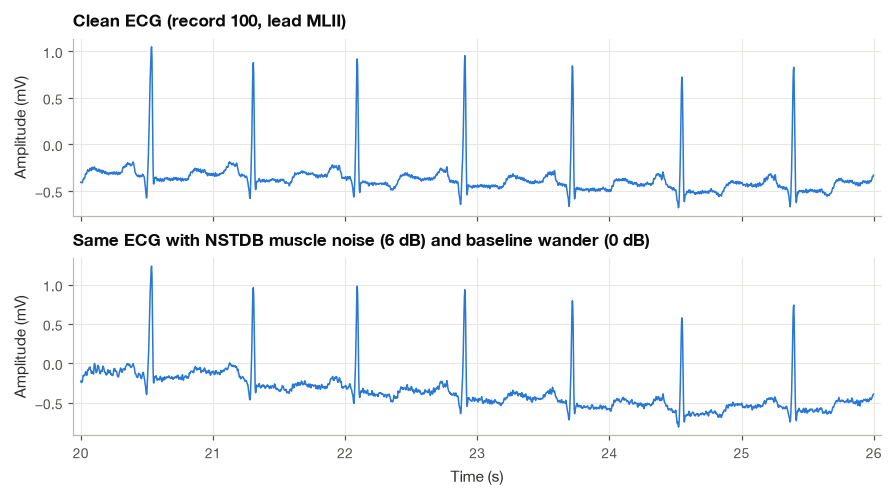

In [21]:
view = (t1 >= 20) & (t1 < 26)
fig, axes = plt.subplots(2, 1, figsize=(8, 4.4), sharex=True)
axes[0].plot(t1[view], clean[view], color=C[0], lw=1.0)
axes[0].set(ylabel="Amplitude (mV)", title="Clean ECG (record 100, lead MLII)")
axes[1].plot(t1[view], noisy[view], color=C[0], lw=1.0)
axes[1].set(xlabel="Time (s)", ylabel="Amplitude (mV)",
            title="Same ECG with NSTDB muscle noise (6 dB) and baseline wander (0 dB)")
plt.show()

### Step 3: Inspect the spectrum

Before designing a filter I always look at the spectrum. We estimate the power spectral density with Welch's method, which averages the periodograms of overlapping 4 s segments and is far smoother than the single FFT of A.5.

721 frequency bins, resolution 0.25 Hz
power below 0.5 Hz: clean 0.0004 mV², noisy 0.0103 mV²


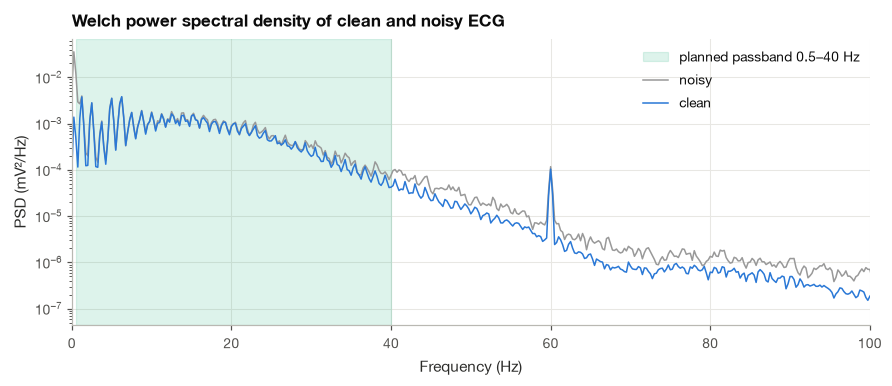

In [22]:
f_w, psd_clean = signal.welch(clean, fs=fs, nperseg=4 * fs)
_, psd_noisy = signal.welch(noisy, fs=fs, nperseg=4 * fs)
print(f"{f_w.size} frequency bins, resolution {f_w[1]:.2f} Hz")
print(f"power below 0.5 Hz: clean {psd_clean[f_w < 0.5].sum() * f_w[1]:.4f} mV², "
      f"noisy {psd_noisy[f_w < 0.5].sum() * f_w[1]:.4f} mV²")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.axvspan(0.5, 40, color=C[2], alpha=0.15, label="planned passband 0.5–40 Hz")
ax.semilogy(f_w, psd_noisy, color="0.6", lw=1.0, label="noisy")
ax.semilogy(f_w, psd_clean, color=C[0], lw=1.0, label="clean")
ax.set(xlim=(0, 100), xlabel="Frequency (Hz)", ylabel="PSD (mV²/Hz)",
       title="Welch power spectral density of clean and noisy ECG")
ax.legend(loc="upper right")
plt.show()

The picture explains the plan. Baseline wander piles up power below about 0.5 Hz, roughly 25 times what the clean ECG has there, according to the printed band powers. Muscle noise is broadband: it lifts the spectrum by a modest factor at all frequencies, and above 40 Hz, where little ECG power remains, it is as strong as the ECG itself. Cutting below 0.5 Hz and above 40 Hz should therefore remove most of the wander and part of the muscle noise while sacrificing little of the ECG. The narrow line at 60 Hz in the clean spectrum is power-line interference already present in the original recording, which was made in the United States (Section 18.4).

### Step 4: Design and apply a band-pass filter

A fourth-order Butterworth band-pass filter from 0.5 to 40 Hz removes both the slow wander and the high-frequency part of the muscle noise. I chose 0.5 Hz as the lower edge because it lies below the slowest heart rates of interest, and 40 Hz as the upper edge because it keeps the QRS energy while cutting the band where Step 3 showed noise dominating. We apply it with `sosfiltfilt`, which runs the filter forward and then backward so that the phase shifts cancel and the R peaks stay where they were; the price is that it needs the whole record in advance, which makes it an offline tool (Section 15.3). To judge the result fairly, we compare the filtered noisy signal with the clean signal passed through the same filter, so that we measure only the noise that remains.

In [23]:
sos = signal.butter(4, [0.5, 40], btype="bandpass", fs=fs, output="sos")
filtered = signal.sosfiltfilt(sos, noisy)
clean_bp = signal.sosfiltfilt(sos, clean)

print(f"{sos.shape[0]} second-order sections")
print(f"SNR before filtering: {snr_db(clean, noisy):5.1f} dB")
print(f"SNR after filtering : {snr_db(clean_bp, filtered):5.1f} dB")
for name, v in [("baseline wander", v_bw), ("muscle noise", v_ma)]:
    kept = np.var(signal.sosfiltfilt(sos, v)) / np.var(v)
    print(f"{name:<16}: {100 * (1 - kept):.0f} % of its power removed")

4 second-order sections
SNR before filtering:  -0.9 dB
SNR after filtering :   9.3 dB
baseline wander : 98 % of its power removed
muscle noise    : 67 % of its power removed


The filter gains about 10 dB. Filtering the two noise records separately shows where the gain comes from: the filter removes about 98 % of the baseline-wander power but only about two thirds of the muscle-noise power. What remains is muscle noise *inside* the 0.5–40 Hz band, which overlaps the ECG and cannot be removed by any fixed linear filter without distorting the waveform; Chapter 10 and Section 18.3 take up that harder problem.

### Step 5: Detect the R peaks and score them

`signal.find_peaks` returns the indices of local maxima that satisfy conditions we choose. We set the height threshold at half of the 99.5th percentile of the filtered signal, which follows the R-wave amplitude but ignores a single extreme noise spike, and a minimum distance of 300 ms, a refractory period that allows heart rates up to 200 bpm. To score the detections we build, by broadcasting, the matrix of distances between every detection and every reference beat; reducing it along one axis asks "was every beat found?", and along the other "does every detection correspond to a beat?".

In [24]:
threshold = 0.5 * np.percentile(filtered, 99.5)
peaks, _ = signal.find_peaks(filtered, height=threshold, distance=sec_to_idx(0.3, fs))

dist = np.abs(peaks[:, None] - r_ref[None, :])        # (n_detected, n_reference)
tol = sec_to_idx(0.05, fs)
found = dist.min(axis=0) <= tol
false_pos = dist.min(axis=1) > tol
print(f"threshold {threshold:.2f} mV, {peaks.size} detections")
print(f"found {found.sum()} of {r_ref.size} reference beats within ±50 ms, false detections: {false_pos.sum()}")

threshold 0.56 mV, 74 detections
found 74 of 74 reference beats within ±50 ms, false detections: 0


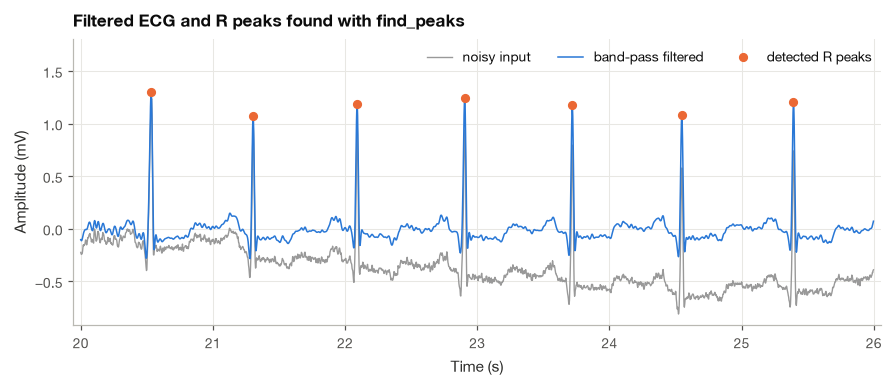

In [25]:
fig, ax = plt.subplots(figsize=(8, 3.4))
pk = peaks[(t1[peaks] >= 20) & (t1[peaks] < 26)]
ax.plot(t1[view], noisy[view], color="0.6", lw=0.9, label="noisy input")
ax.plot(t1[view], filtered[view], color=C[0], lw=1.0, label="band-pass filtered")
ax.plot(t1[pk], filtered[pk], "o", color=C[1], ms=5, label="detected R peaks")
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="Filtered ECG and R peaks found with find_peaks")
ax.legend(loc="upper right", ncols=3)
ax.set_ylim(top=ax.get_ylim()[1] + 0.4)
plt.show()

Every beat is found and nothing else is. Record 100 is an easy case even with this much noise, because its R waves are tall and its rhythm is regular; Exercise 6 asks you to try the same detector on a genuinely difficult record.

### Step 6: Tabulate the detections with pandas

Arrays are ideal for samples, but results (one row per beat, with a time, an amplitude, an RR interval and a label) are naturally tabular, and pandas handles them well. A `DataFrame` is a table whose columns can have different types and whose rows can be filtered, grouped and summarized with readable one-liners. We label each detection with the symbol of its nearest reference beat and compute RR intervals with `.diff()`.

In [26]:
nearest = dist.argmin(axis=1)
det = pd.DataFrame({
    "time_s": t1[peaks],
    "amplitude_mV": filtered[peaks],
    "symbol": np.where(false_pos, "?", sym_ref[nearest]),
})
det["rr_s"] = det["time_s"].diff()
det["hr_bpm"] = 60 / det["rr_s"]
det.head().round(3)

,time_s,amplitude_mV,symbol,rr_s,hr_bpm
0,0.214,1.139,N,NaN,NaN
1,1.028,1.226,N,0.814,73.720
2,1.839,1.157,N,0.811,73.973
3,2.628,1.408,N,0.789,76.056
4,3.419,0.873,N,0.792,75.789


In [27]:
print(det.groupby("symbol")[["amplitude_mV", "rr_s"]].mean().round(3).to_string())
print(f"\nmean heart rate {det['hr_bpm'].mean():.1f} bpm, "
      f"range {det['hr_bpm'].min():.1f}–{det['hr_bpm'].max():.1f} bpm")

        amplitude_mV   rr_s
symbol                     
A              1.261  0.653
N              1.154  0.814

mean heart rate 74.0 bpm, range 60.3–91.9 bpm


The single atrial premature beat (`A`) in this minute stands out at once: it arrives after a much shorter RR interval than the normal beats, which is exactly what "premature" means. It accounts for both ends of the heart-rate range: the premature beat itself gives the maximum, and the long pause that follows it, before the sinus node fires again, gives the minimum.

### Step 7: Summarize the whole record from its annotations

The same tools scale to the full 30-minute annotation file. We load all 2274 annotations; the rhythm labels in `aux_note` carry a trailing null character that we strip.

In [28]:
ann_all = wfdb.rdann("../data/mitdb/100", "atr")
df = pd.DataFrame({
    "sample": ann_all.sample,
    "symbol": ann_all.symbol,
    "aux": [a.rstrip("\x00") for a in ann_all.aux_note],
})
df["time_s"] = df["sample"] / ann_all.fs
print(df["symbol"].value_counts().to_string())

symbol
N    2239
A      33
+       1
V       1


The single `+` is a rhythm annotation (with the note `(N`, normal sinus rhythm) rather than a beat, so we keep only the beat symbols before computing RR intervals, and we group them by beat type:

In [29]:
beats_df = df[df["symbol"].isin(["N", "A", "V"])].copy()
beats_df["rr_s"] = beats_df["time_s"].diff()
beats_df["hr_bpm"] = 60 / beats_df["rr_s"]

summary = (beats_df.groupby("symbol")["rr_s"]
           .agg(count="count", mean_rr_s="mean", std_rr_s="std")
           .round(3))
summary

,count,mean_rr_s,std_rr_s
symbol,,,
A,33,0.594,0.041
N,2238,0.798,0.042
V,1,0.536,NaN


Over the whole record the 33 atrial premature beats follow an RR interval of 0.59 s on average, against 0.80 s for normal beats. (The `count` column counts valid RR intervals, which is why it shows 2238 normal beats instead of 2239: the very first beat has no predecessor.) Finally, grouping by minute gives the heart-rate trend. The record lasts 30.1 minutes, so we keep only the 30 complete minutes to avoid a misleading average over the last few seconds.

In [30]:
complete = beats_df[beats_df["time_s"] < 30 * 60]
per_minute = complete.groupby((complete["time_s"] // 60).astype(int))["hr_bpm"].mean()
print(f"{per_minute.size} complete minutes, heart rate {per_minute.min():.1f}–{per_minute.max():.1f} bpm, "
      f"overall mean {complete['hr_bpm'].mean():.1f} bpm")
print(f"fastest minute: minute {per_minute.idxmax()} ({per_minute.max():.1f} bpm)")

30 complete minutes, heart rate 73.7–80.1 bpm, overall mean 75.8 bpm
fastest minute: minute 6 (80.1 bpm)


## A.8 Reproducibility, Speed and Common Pitfalls

### Random seeds

Many examples add simulated noise, split data at random or initialize a neural network. To make such results reproducible, every notebook in the book creates a random generator with a fixed seed in its setup cell, `rng = np.random.default_rng(42)`, and draws all random numbers from it. Two generators created with the same seed produce identical sequences:

In [31]:
noise_a = np.random.default_rng(2024).normal(0, 0.05, 4)
noise_b = np.random.default_rng(2024).normal(0, 0.05, 4)
noise_c = np.random.default_rng(2025).normal(0, 0.05, 4)
print(f"seed 2024 twice: {noise_a} and {noise_b} -> identical: {np.array_equal(noise_a, noise_b)}")
print(f"seed 2025      : {noise_c}")

seed 2024 twice: [ 0.0514  0.0821  0.0573 -0.0487] and [ 0.0514  0.0821  0.0573 -0.0487] -> identical: True
seed 2025      : [-0.1111  0.0013 -0.0269 -0.0565]


I recommend this `Generator` interface over the older global `np.random.seed`, and passing the generator into functions that need randomness instead of letting each function reseed. Libraries have their own seeds: scikit-learn estimators take a `random_state` argument, and PyTorch uses `torch.manual_seed` (Chapter 27).

### Loops versus vectorized code

To see why vectorization matters, we compute a 100 ms moving average (36 samples) of five minutes of ECG in three ways: a Python loop that averages each window, a convolution with a box of ones, and a running-sum trick that uses `np.cumsum`. The moving average itself is studied in Section 13.3; here it is simply a test workload.

In [32]:
x5 = wfdb.rdrecord("../data/mitdb/100", sampto=5 * 60 * fs).p_signal[:, 0]
L = sec_to_idx(0.1, fs)


def moving_average_loop(x, L):
    """Moving average with an explicit Python loop (valid part only)."""
    y = np.empty(x.size - L + 1)
    for n in range(y.size):
        y[n] = x[n:n + L].mean()
    return y


def moving_average_cumsum(x, L):
    """Moving average from differences of a running sum."""
    c = np.cumsum(np.concatenate(([0.0], x)))
    return (c[L:] - c[:-L]) / L


def best_time(fn, repeats=3):
    """Shortest wall-clock time of several runs, in seconds."""
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        out = fn()
        times.append(time.perf_counter() - t0)
    return min(times), out


t_loop, y_loop = best_time(lambda: moving_average_loop(x5, L), repeats=1)
t_conv, y_conv = best_time(lambda: np.convolve(x5, np.ones(L) / L, mode="valid"))
t_csum, y_csum = best_time(lambda: moving_average_cumsum(x5, L))

print(f"{x5.size} samples, window {L} samples")
print(f"Python loop   : {1000 * t_loop:8.1f} ms")
print(f"np.convolve   : {1000 * t_conv:8.2f} ms  ({t_loop / t_conv:,.0f}x faster)")
print(f"cumsum trick  : {1000 * t_csum:8.2f} ms  ({t_loop / t_csum:,.0f}x faster)")
print(f"max difference loop vs convolve: {np.max(np.abs(y_loop - y_conv)):.1e} mV, "
      f"loop vs cumsum: {np.max(np.abs(y_loop - y_csum)):.1e} mV")

108000 samples, window 36 samples
Python loop   :    140.5 ms
np.convolve   :     1.19 ms  (118x faster)
cumsum trick  :     0.48 ms  (294x faster)
max difference loop vs convolve: 3.3e-16 mV, loop vs cumsum: 1.4e-12 mV


The three versions agree to within rounding error, and the vectorized ones are faster by two orders of magnitude or more (the exact factors depend on the computer). The loop pays the cost of the Python interpreter for every one of the 108,000 windows, while `np.convolve` and `np.cumsum` each run one compiled loop. The cumsum version does a fixed amount of work per sample no matter how long the window is, but it subtracts two large, nearly equal running sums, so its rounding error grows slowly with record length. For very long recordings, `np.convolve` or `scipy.signal.lfilter` is the safer choice.

### Integer overflow with raw ADC data

The MIT-BIH records are stored as 11-bit integer codes from the analog-to-digital converter. Physical units are recovered as

$$
x_{\text{mV}}[n] = \frac{d[n] - b}{g},
$$

where $d[n]$ is the stored code, $b$ the baseline code (1024 for record 100) and $g$ the gain (200 codes per mV). Reading with `physical=False` returns the codes in `d_signal`. With its default settings `wfdb` 4.3 returns them as 64-bit integers, which is safe. The danger appears when integer data arrive in a narrow type: request `return_res=16`, read an EDF file's raw samples, or load a binary file from your own hardware with `np.fromfile(..., dtype=np.int16)`, and you hold `int16` values whose largest representable number is 32,767. NumPy integer arithmetic on arrays wraps around silently when it overflows.

In [33]:
r16 = wfdb.rdrecord("../data/mitdb/100", sampto=3600, physical=False, return_res=16)
d = r16.d_signal[:, 0]
d64 = wfdb.rdrecord("../data/mitdb/100", sampto=3600, physical=False).d_signal[:, 0]

print(f"default d_signal dtype: {d64.dtype}; with return_res=16: {d.dtype}")
print(f"first code {d[0]}; d**2 in int16 = {(d**2)[0]}, correct value = {int(d[0])**2}")
print(f"energy in int16      : {np.sum(d * d):,}")
print(f"energy in int64      : {np.sum(d.astype(np.int64)**2):,}")

mv = (d.astype(np.float64) - r16.baseline[0]) / r16.adc_gain[0]
print(f"(d - baseline) / gain matches p_signal: {np.allclose(mv, ecg)}")

default d_signal dtype: int64; with return_res=16: int16
first code 995; d**2 in int16 = 6985, correct value = 990025
energy in int16      : -10,334,478
energy in int64      : 3,322,040,050
(d - baseline) / gain matches p_signal: True


The first code is 995, whose square is 990,025, but the `int16` result is 6,985: the true value modulo $2^{16}$. The "energy" computed in `int16` even comes out negative. The fix is to convert to floating point (or at least to `int64`) before doing any arithmetic, which is exactly what `p_signal` does for us.

```{important}
Never do arithmetic on raw ADC codes in their storage type. Convert to `float64` first, or read the physical signal (`p_signal`, or `get_data()` in MNE), which is already in floating point.
```

### Off-by-one errors and time vectors

Two functions that build time vectors behave differently at the end point. `np.arange(start, stop, step)` excludes `stop` in exact arithmetic, but with a floating-point step it can include it. `np.linspace(start, stop, num)` includes `stop` by default, so the spacing is `(stop - start) / (num - 1)`, not `(stop - start) / num`.

In [34]:
print(f"np.arange(1, 1.3, 0.1)        -> {np.arange(1, 1.3, 0.1)}  (stop value included)")
step = np.diff(np.linspace(0, 2, 720))[0]
print(f"np.linspace(0, 2, 720) step   -> {step:.7f} s, but 1/fs = {1 / fs:.7f} s")
print(f"np.arange(720) / fs step      -> {np.diff(np.arange(720) / fs)[0]:.7f} s")

np.arange(1, 1.3, 0.1)        -> [1.  1.1 1.2 1.3]  (stop value included)
np.linspace(0, 2, 720) step   -> 0.0027816 s, but 1/fs = 0.0027778 s
np.arange(720) / fs step      -> 0.0027778 s


A time vector built with `linspace` in this way is stretched by one part in 719, so after 30 minutes of recording its time stamps would be off by 2.5 s. The rule `t = np.arange(N) / fs` avoids both problems.

### Comparing floating-point numbers

Decimal fractions such as 0.1 have no exact binary representation, so arithmetic that is exact on paper is not exact in the computer, and `==` between floats is unreliable. Looking up a time stamp by equality is a classic way to get an empty result.

In [35]:
print(f"0.1 + 0.2 == 0.3          : {0.1 + 0.2 == 0.3}  (0.1 + 0.2 = {0.1 + 0.2!r})")
t_bad = np.arange(0, 10, 1 / fs)
print(f"indices where t == 0.7    : {np.flatnonzero(t_bad == 0.7)}")
print(f"indices where isclose(t, 0.7): {np.flatnonzero(np.isclose(t_bad, 0.7))}")
print(f"index arithmetic          : {sec_to_idx(0.7, fs)}")

0.1 + 0.2 == 0.3          : False  (0.1 + 0.2 = 0.30000000000000004)
indices where t == 0.7    : []
indices where isclose(t, 0.7): [252]
index arithmetic          : 252


Use `np.isclose` (or `np.allclose` for whole arrays) to compare floats, and better still, work with integer sample indices and convert to seconds only for display.

The table gathers the pitfalls of this appendix with their symptoms and fixes.

| Symptom | Cause | Fix |
|---|---|---|
| Energy or power is negative or absurd | `int16` ADC codes squared or multiplied | Convert with `.astype(np.float64)` or use `p_signal` |
| Arrays differ in length by one | `np.diff` drops a sample; slice end is exclusive | Plot `np.diff(x)` against `t[1:]`; slice `x[i1:i2]` has `i2 - i1` samples |
| Time axis slowly drifts | `np.linspace(0, T, N)` used as a time vector | `t = np.arange(N) / fs` |
| Time stamp not found | `t == 0.7` on floats | `np.isclose`, or integer indices |
| Original signal changed unexpectedly | Writing into a slice (a view) | `.copy()` before modifying |
| Results change on every run | Unseeded random numbers | `rng = np.random.default_rng(seed)` |
| Wrong channel analyzed | Channel order differs between records (BIDMC) | Select channels by name, not position |

## Summary

NumPy arrays hold numbers of one type in one block of memory, and nearly everything we do to an ECG (scaling, centering, differencing, averaging) is a vectorized expression on such an array. Time vectors are built from sample indices, windows are cut with half-open slices whose length is `stop - start`, and Boolean masks and integer index arrays select samples by condition or by annotation. Broadcasting turns the common task of cutting a recording into beats into a single indexing operation, and the same `(n, 1)` against `(1, L)` pattern reappears in peak scoring, template matching and averaging. `np.fft.rfft` and the routines of `scipy.signal` cover the classical toolbox, and the seven-step walkthrough of A.7 (load, add noise at a known SNR, inspect the spectrum, filter, detect, tabulate, summarize) is a template I return to constantly; Section 18.5 builds a complete preprocessing pipeline on the same skeleton.

The pitfalls are few but they recur: integer overflow with narrow ADC types, off-by-one errors in slices and time vectors, equality tests on floats, writes into views, and unseeded random numbers. Each has a simple remedy, and following them from the start saves hours of debugging later. The chapters that follow assume the idioms in this appendix, from the first-difference systems of [Chapter 3](../ch04_systems/index.md) to the 1D convolutional networks of Chapter 27.

## Exercises

1. Load the first 10 s of lead V5 (channel 1) of record 100. Build the time vector, then compute the mean, the RMS after mean removal and the peak-to-peak amplitude in mV. Plot two seconds of the signal with correctly labeled axes.
2. The largest `int16` value is 32,767. Above which ADC code does squaring an `int16` value overflow? Read 10 s of record 100 with `physical=False, return_res=16`, count how many samples exceed that code, and explain why the `int16` energy in A.8 is wrong even though the codes themselves fit comfortably in 16 bits.
3. Using the broadcasting approach of A.3 on the full record 100, build one beat matrix for the normal beats and one for the 33 atrial premature beats. Plot the two mean beats on the same axes. Which part of the waveform differs, and why would you expect that from the physiology of an atrial ectopic beat?
4. Repeat Steps 2 to 5 of A.7 with the electrode-motion noise record `em` instead of `ma`, at SNRs of 6, 0 and −6 dB. Tabulate the SNR after filtering, the number of beats found and the number of false detections with pandas. Why does electrode-motion noise defeat the band-pass filter much more than muscle noise does? (Look at its Welch spectrum.)
5. Write `moving_average_cumsum` for the full 30-minute record (650,000 samples) and compare it with `np.convolve`. Plot the absolute difference against time. How does the discrepancy grow, and how could you reduce it while keeping the speed of the running-sum approach? (Hint: restart the running sum in blocks.)
6. Apply the band-pass filter and `find_peaks` detector of A.7 to the first 5 minutes of the very noisy record 105, scoring the detections against its annotations. Report the fraction of reference beats found and the number of false detections for several values of the height threshold, and explain the trade-off you observe.

## Further Reading

The design of NumPy and the reasons vectorized array code is fast are described by {cite:t}`harris2020`, and SciPy's signal processing module, including its filter design and spectral estimation routines, by {cite:t}`virtanen2020`. {cite:t}`hunter2007` introduces Matplotlib, and {cite:t}`mckinney2010` presents the data structures behind pandas. The PhysioNet resource that hosts the databases used throughout this book is described by {cite:t}`goldberger2000`, the noise records of the walkthrough by {cite:t}`moody1984`, and the online documentation of the `wfdb` package explains the signal formats (such as the format 212 encoding of the MIT-BIH records) in detail.